In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

train = pd.read_csv(ROOT / "train.csv")
series = pd.read_csv(ROOT / "train_series.csv")

print("Training studies:", len(train))
print("Training series:", len(series))

print("\nTrain columns:")
print(train.columns.tolist())

Training studies: 4407
Training series: 24371

Train columns:
['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


In [2]:
print("Train columns:")
print(train.columns.tolist())

display(train.head())

column_summary = pd.DataFrame({
    "dtype": train.dtypes,
    "non_missing": train.notna().sum(),
    "missing": train.isna().sum(),
    "unique_values": train.nunique(),
})

display(column_summary)

print("Series columns:")
print(series.columns.tolist())

Train columns:
['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,non_missing,missing,unique_values
StudyInstanceUID,object,4407,0,4407
Report,object,4407,0,4276
ACL,float64,58,4349,2
MCL,float64,58,4349,2
Medial Meniscus,float64,58,4349,2
Lateral Meniscus,float64,58,4349,2
Medial OA,float64,58,4349,2
Lateral OA,float64,58,4349,2
PF OA,float64,58,4349,2
Effusion,float64,58,4349,2


Series columns:
['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


In [3]:
target_columns = [
    "ACL", "MCL",
    "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

labels_present = train[target_columns].notna().sum(axis=1)

labelled = train.loc[labels_present == len(target_columns)].copy()
partial = train.loc[
    (labels_present > 0) & (labels_present < len(target_columns))
].copy()
unlabelled = train.loc[labels_present == 0].copy()

print("Fully labelled:", len(labelled))
print("Partially labelled:", len(partial))
print("Unlabelled:", len(unlabelled))

print(
    "Duplicate study IDs:",
    train["StudyInstanceUID"].duplicated().sum(),
)

Fully labelled: 58
Partially labelled: 0
Unlabelled: 4349
Duplicate study IDs: 0


In [4]:
label_summary = pd.DataFrame({
    "negative": (labelled[target_columns] == 0).sum(),
    "positive": (labelled[target_columns] == 1).sum(),
    "other_values": (
        labelled[target_columns].notna()
        & ~labelled[target_columns].isin([0, 1])
    ).sum(),
})

label_summary["positive_percent"] = (
    label_summary["positive"] / max(len(labelled), 1) * 100
).round(1)

display(label_summary)

,negative,positive,other_values,positive_percent
ACL,34,24,0,41.4
MCL,49,9,0,15.5
Medial Meniscus,32,26,0,44.8
Lateral Meniscus,35,23,0,39.7
Medial OA,43,15,0,25.9
Lateral OA,47,11,0,19.0
PF OA,37,21,0,36.2
Effusion,23,35,0,60.3
Synovitis,31,27,0,46.6
Baker's,46,12,0,20.7


In [5]:
# Sort first so the split is reproducible even if CSV row order changes.
labelled_sorted = (
    labelled
    .sort_values("StudyInstanceUID")
    .reset_index(drop=True)
)

rng = np.random.default_rng(42)
indices = rng.permutation(len(labelled_sorted))

n_validation = int(np.ceil(0.20 * len(labelled_sorted)))

validation_studies = labelled_sorted.iloc[
    indices[:n_validation]
].copy()

training_studies = labelled_sorted.iloc[
    indices[n_validation:]
].copy()

# Confirm studies do not overlap.
assert set(training_studies["StudyInstanceUID"]).isdisjoint(
    set(validation_studies["StudyInstanceUID"])
)

print("Training studies:", len(training_studies))
print("Validation studies:", len(validation_studies))

Training studies: 46
Validation studies: 12


In [6]:
split_summary = pd.DataFrame({
    "train_positive": training_studies[target_columns].eq(1).sum(),
    "train_negative": training_studies[target_columns].eq(0).sum(),
    "val_positive": validation_studies[target_columns].eq(1).sum(),
    "val_negative": validation_studies[target_columns].eq(0).sum(),
})

split_summary["both_classes_present"] = (
    split_summary[
        ["train_positive", "train_negative",
         "val_positive", "val_negative"]
    ] > 0
).all(axis=1)

display(split_summary)

,train_positive,train_negative,val_positive,val_negative,both_classes_present
ACL,18,28,6,6,True
MCL,6,40,3,9,True
Medial Meniscus,18,28,8,4,True
Lateral Meniscus,20,26,3,9,True
Medial OA,13,33,2,10,True
Lateral OA,8,38,3,9,True
PF OA,16,30,5,7,True
Effusion,27,19,8,4,True
Synovitis,19,27,8,4,True
Baker's,9,37,3,9,True


In [7]:
from pathlib import Path

split_manifest = pd.concat([
    training_studies[["StudyInstanceUID"]].assign(split="train"),
    validation_studies[["StudyInstanceUID"]].assign(split="validation"),
], ignore_index=True)

split_manifest = split_manifest.sort_values(
    "StudyInstanceUID"
).reset_index(drop=True)

assert len(split_manifest) == 58
assert split_manifest["StudyInstanceUID"].is_unique

output_path = Path("/kaggle/working/study_split_seed42.csv")
split_manifest.to_csv(output_path, index=False)

print("Saved:", output_path)
print(split_manifest["split"].value_counts())

Saved: /kaggle/working/study_split_seed42.csv
split
train         46
validation    12
Name: count, dtype: int64


In [8]:
# Attach the saved split assignments to all available series
# belonging to the 58 labelled studies.
candidate_series = series.merge(
    split_manifest,
    on="StudyInstanceUID",
    how="inner",
    validate="many_to_one",
)

print("Studies represented:",
      candidate_series["StudyInstanceUID"].nunique())
print("Available series:", len(candidate_series))

# Count series per study and anatomical plane.
plane_counts = pd.crosstab(
    candidate_series["StudyInstanceUID"],
    candidate_series["Anatomical_Plane"],
).reindex(
    index=split_manifest["StudyInstanceUID"],
    columns=["Sagittal", "Coronal", "Axial"],
    fill_value=0,
)

display(plane_counts.head())

print("Studies missing each plane:")
print(plane_counts.eq(0).sum())

print("\nSeries by plane and acquisition flags:")
display(
    candidate_series.groupby(
        ["Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression"],
        dropna=False,
    ).size().reset_index(name="series_count")
)

Studies represented: 58
Available series: 336


Anatomical_Plane,Sagittal,Coronal,Axial
StudyInstanceUID,,,
1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149,2,2,1
1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269,3,3,3
1.2.826.0.1.3680043.8.498.10306159113324811538703788080836752052,2,3,2
1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580,3,1,1
1.2.826.0.1.3680043.8.498.11382021393803389951964005983002209238,3,4,2


Studies missing each plane:
Anatomical_Plane
Sagittal    0
Coronal     0
Axial       0
dtype: int64

Series by plane and acquisition flags:


,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,series_count
0,Axial,0,0,18
1,Axial,1,1,63
2,Coronal,0,0,54
3,Coronal,1,1,65
4,Sagittal,0,0,72
5,Sagittal,1,1,64


In [9]:
preferred_series = candidate_series.loc[
    candidate_series["Fluid_Sensitive"].eq(1)
    & candidate_series["Fat_Suppression"].eq(1)
].copy()

preferred_counts = pd.crosstab(
    preferred_series["StudyInstanceUID"],
    preferred_series["Anatomical_Plane"],
).reindex(
    index=split_manifest["StudyInstanceUID"],
    columns=["Sagittal", "Coronal", "Axial"],
    fill_value=0,
)

coverage_summary = pd.DataFrame({
    "no_matching_series": preferred_counts.eq(0).sum(),
    "exactly_one": preferred_counts.eq(1).sum(),
    "multiple_matches": preferred_counts.gt(1).sum(),
})

display(coverage_summary)

needs_review = preferred_counts.loc[
    preferred_counts.ne(1).any(axis=1)
]

print("Studies needing a fallback or tie-break:", len(needs_review))
display(needs_review)

,no_matching_series,exactly_one,multiple_matches
Anatomical_Plane,,,
Sagittal,2,48,8
Coronal,2,48,8
Axial,0,53,5


Studies needing a fallback or tie-break: 22


Anatomical_Plane,Sagittal,Coronal,Axial
StudyInstanceUID,,,
1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269,1,1,2
1.2.826.0.1.3680043.8.498.10306159113324811538703788080836752052,1,2,2
1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580,2,1,1
1.2.826.0.1.3680043.8.498.11382021393803389951964005983002209238,1,3,1
1.2.826.0.1.3680043.8.498.11548045715264151632153040089882701935,1,2,1
1.2.826.0.1.3680043.8.498.11771393824519892797114773408583976756,2,1,1
1.2.826.0.1.3680043.8.498.12448079646359892252441208258836556945,1,1,2
1.2.826.0.1.3680043.8.498.12606657226568558340797193167488111973,1,2,1
1.2.826.0.1.3680043.8.498.13267780356245120052411517053322874891,2,1,1


In [10]:
review_series = candidate_series.loc[
    candidate_series["StudyInstanceUID"].isin(needs_review.index)
].copy()

review_series["preferred"] = (
    review_series["Fluid_Sensitive"].eq(1)
    & review_series["Fat_Suppression"].eq(1)
)

# Read one header per candidate series, without loading image pixels.
records = []

import pydicom

for _, row in review_series.iterrows():
    folder = (
        ROOT / "train_series"
        / row["StudyInstanceUID"]
        / row["SeriesInstanceUID"]
    )

    files = sorted(folder.glob("*.dcm"))

    record = {
        "StudyInstanceUID": row["StudyInstanceUID"],
        "SeriesInstanceUID": row["SeriesInstanceUID"],
        "Plane": row["Anatomical_Plane"],
        "preferred": row["preferred"],
        "file_count": len(files),
    }

    if files:
        header = pydicom.dcmread(files[0], stop_before_pixels=True)

        record.update({
            "description": getattr(header, "SeriesDescription", None),
            "rows": getattr(header, "Rows", None),
            "columns": getattr(header, "Columns", None),
            "pixel_spacing": str(getattr(header, "PixelSpacing", None)),
            "slice_thickness": getattr(header, "SliceThickness", None),
        })

    records.append(record)

selection_review = pd.DataFrame(records)

display(
    selection_review.sort_values(
        ["StudyInstanceUID", "Plane", "SeriesInstanceUID"]
    )
)

selection_review.to_csv(
    "/kaggle/working/series_selection_review.csv",
    index=False,
)

,StudyInstanceUID,SeriesInstanceUID,Plane,preferred,file_count,description,rows,columns,pixel_spacing,slice_thickness
2,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.25511961362790207336...,Axial,True,16,RT.COR ACL T2W FS,480,480,"[0.27083334326744, 0.27083334326744]",2.5
7,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.71876353677262220297...,Axial,True,40,RT.Tra_T2W_TSE_SPAIR,640,640,"[0.25, 0.25]",3.0
8,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.80784574440782299658...,Axial,False,40,RT.Tra_T1W_TSE,704,704,"[0.22727273404598, 0.22727273404598]",3.0
0,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.10560750949481691706...,Coronal,False,30,RT.Cor_TSE_T2,640,640,"[0.25, 0.25]",3.0
1,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.11485276391165564447...,Coronal,False,30,RT.Cor_T1W_TSE,704,704,"[0.22727273404598, 0.22727273404598]",3.0
...,...,...,...,...,...,...,...,...,...,...
136,1.2.826.0.1.3680043.8.498.97274720257634584071...,1.2.826.0.1.3680043.8.498.12306898793869915364...,Axial,False,34,pd_tse_tra_d,960,960,"[0.1562, 0.1562]",3.0
139,1.2.826.0.1.3680043.8.498.97274720257634584071...,1.2.826.0.1.3680043.8.498.92909718893560498250...,Axial,True,160,t2_de3d_we_tra_Patella_fit_T,640,1280,"[0.25, 0.25]",0.6
140,1.2.826.0.1.3680043.8.498.97274720257634584071...,1.2.826.0.1.3680043.8.498.96963728552261384768...,Coronal,True,32,pd_tse_fs_cor_d,640,640,"[0.2813, 0.2813]",3.0
137,1.2.826.0.1.3680043.8.498.97274720257634584071...,1.2.826.0.1.3680043.8.498.17378665248295186489...,Sagittal,False,36,t2_tse_sag_d,800,800,"[0.1875, 0.1875]",3.0


In [11]:
keys = ["StudyInstanceUID", "SeriesInstanceUID"]

selection_candidates = candidate_series.merge(
    selection_review[keys + ["description"]],
    on=keys,
    how="left",
    validate="one_to_one",
)

selection_candidates["preferred"] = (
    selection_candidates["Fluid_Sensitive"].eq(1)
    & selection_candidates["Fat_Suppression"].eq(1)
)

# Description-based heuristic, not a verified anatomical classification.
selection_candidates["targeted_description"] = (
    selection_candidates["description"]
    .fillna("")
    .str.contains(r"ACL|PCL|OBL", case=False, regex=True)
)

selected_series = (
    selection_candidates
    .sort_values(
        [
            "StudyInstanceUID",
            "Anatomical_Plane",
            "preferred",
            "targeted_description",
            "SeriesInstanceUID",
        ],
        ascending=[True, True, False, True, True],
    )
    .drop_duplicates(
        ["StudyInstanceUID", "Anatomical_Plane"],
        keep="first",
    )
    .copy()
)

selected_series["used_fallback"] = ~selected_series["preferred"]

assert len(selected_series) == 58 * 3
assert selected_series.groupby("StudyInstanceUID").size().eq(3).all()

print("Selected series:", len(selected_series))
print("Studies:", selected_series["StudyInstanceUID"].nunique())
print("Fallback selections:", selected_series["used_fallback"].sum())

display(pd.crosstab(
    selected_series["split"],
    selected_series["Anatomical_Plane"],
))

Selected series: 174
Studies: 58
Fallback selections: 4


Anatomical_Plane,Axial,Coronal,Sagittal
split,,,
train,46,46,46
validation,12,12,12


In [12]:
dataset_manifest = selected_series.merge(
    labelled[["StudyInstanceUID"] + target_columns],
    on="StudyInstanceUID",
    how="left",
    validate="many_to_one",
)

# Store paths relative to ROOT so the manifest remains portable.
dataset_manifest["series_relative_path"] = (
    "train_series/"
    + dataset_manifest["StudyInstanceUID"]
    + "/"
    + dataset_manifest["SeriesInstanceUID"]
)

assert len(dataset_manifest) == 174
assert dataset_manifest[target_columns].notna().all().all()
assert not dataset_manifest.duplicated(
    ["StudyInstanceUID", "Anatomical_Plane"]
).any()

assert (
    dataset_manifest.groupby("StudyInstanceUID")["split"]
    .nunique().eq(1).all()
)

output_path = Path("/kaggle/working/dataset_manifest_seed42.csv")
dataset_manifest.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Series per split:")
print(dataset_manifest["split"].value_counts())

display(dataset_manifest[
    ["StudyInstanceUID", "Anatomical_Plane",
     "split", "used_fallback"] + target_columns
].head())

Saved: /kaggle/working/dataset_manifest_seed42.csv
Series per split:
split
train         138
validation     36
Name: count, dtype: int64


,StudyInstanceUID,Anatomical_Plane,split,used_fallback,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,Axial,train,False,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.10095687747295410396...,Coronal,train,False,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.10095687747295410396...,Sagittal,train,False,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,1.2.826.0.1.3680043.8.498.10170898615867673028...,Axial,train,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.2.826.0.1.3680043.8.498.10170898615867673028...,Coronal,train,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [13]:
file_checks = []

for _, row in dataset_manifest.iterrows():
    folder = ROOT / row["series_relative_path"]
    files = list(folder.glob("*.dcm"))

    file_checks.append({
        "StudyInstanceUID": row["StudyInstanceUID"],
        "SeriesInstanceUID": row["SeriesInstanceUID"],
        "plane": row["Anatomical_Plane"],
        "folder_exists": folder.is_dir(),
        "dicom_count": len(files),
    })

file_checks = pd.DataFrame(file_checks)

problems = file_checks.loc[
    ~file_checks["folder_exists"]
    | file_checks["dicom_count"].eq(0)
]

print("Series checked:", len(file_checks))
print("Missing or empty series:", len(problems))

print("\nDICOM file counts by plane:")
display(
    file_checks.groupby("plane")["dicom_count"]
    .agg(["min", "median", "max"])
)

if not problems.empty:
    display(problems)

Series checked: 174
Missing or empty series: 0

DICOM file counts by plane:


,min,median,max
plane,,,
Axial,12,32.0,160
Coronal,15,30.0,42
Sagittal,15,29.0,320


In [14]:
largest_series = file_checks.loc[
    file_checks.groupby("plane")["dicom_count"].idxmax()
]

records = []

for _, row in largest_series.iterrows():
    folder = (
        ROOT / "train_series"
        / row["StudyInstanceUID"]
        / row["SeriesInstanceUID"]
    )

    for path in sorted(folder.glob("*.dcm")):
        ds = pydicom.dcmread(path, stop_before_pixels=True)

        position = getattr(ds, "ImagePositionPatient", None)
        orientation = getattr(ds, "ImageOrientationPatient", None)

        records.append({
            "plane": row["plane"],
            "file": path.name,
            "description": str(getattr(ds, "SeriesDescription", "")),
            "rows": getattr(ds, "Rows", None),
            "columns": getattr(ds, "Columns", None),
            "position": (
                tuple(round(float(v), 4) for v in position)
                if position is not None else None
            ),
            "orientation": (
                tuple(round(float(v), 4) for v in orientation)
                if orientation is not None else None
            ),
            "echo_time": str(getattr(ds, "EchoTime", "Missing")),
            "acquisition_number": str(
                getattr(ds, "AcquisitionNumber", "Missing")
            ),
            "frames": int(getattr(ds, "NumberOfFrames", 1)),
        })

largest_headers = pd.DataFrame(records)

summary = largest_headers.groupby("plane").agg(
    files=("file", "size"),
    unique_positions=("position", "nunique"),
    missing_positions=("position", lambda x: x.isna().sum()),
    rounded_orientations=("orientation", "nunique"),
    echo_times=("echo_time", "nunique"),
    acquisition_numbers=("acquisition_number", "nunique"),
    max_frames_per_file=("frames", "max"),
)

display(summary)

display(
    largest_headers[
        ["plane", "description", "rows", "columns"]
    ].drop_duplicates()
)

,files,unique_positions,missing_positions,rounded_orientations,echo_times,acquisition_numbers,max_frames_per_file
plane,,,,,,,
Axial,160,160,0,1,1,1,1
Coronal,42,42,0,1,1,1,1
Sagittal,320,320,0,1,1,1,1


,plane,description,rows,columns
0,Axial,t2_de3d_we_tra_Patella_fit_T,640,1280
160,Coronal,COR T2 FS,256,256
202,Sagittal,SAG 3D_VIEW_PD_SPAIR_HR L,640,640


In [15]:
spacing_records = []

for plane, group in largest_headers.groupby("plane"):
    positions = np.array(group["position"].tolist(), dtype=float)
    orientations = np.array(group["orientation"].tolist(), dtype=float)

    normal = np.cross(orientations[0, :3], orientations[0, 3:])
    normal /= np.linalg.norm(normal)

    # Sort positions along the direction perpendicular to the slices.
    projected_positions = np.sort(positions @ normal)
    spacing = np.diff(projected_positions)

    spacing_records.append({
        "plane": plane,
        "files": len(group),
        "min_spacing_mm": spacing.min(),
        "median_spacing_mm": np.median(spacing),
        "max_spacing_mm": spacing.max(),
        "near_duplicate_positions": int((spacing < 0.001).sum()),
        "approximately_uniform": np.allclose(
            spacing,
            np.median(spacing),
            rtol=0.01,
            atol=0.01,
        ),
    })

spacing_summary = pd.DataFrame(spacing_records)
display(spacing_summary.round(4))

,plane,files,min_spacing_mm,median_spacing_mm,max_spacing_mm,near_duplicate_positions,approximately_uniform
0,Axial,160,0.5999,0.60,0.6001,0,True
1,Coronal,42,3.4800,3.48,3.4801,0,True
2,Sagittal,320,0.3999,0.40,0.4001,0,True


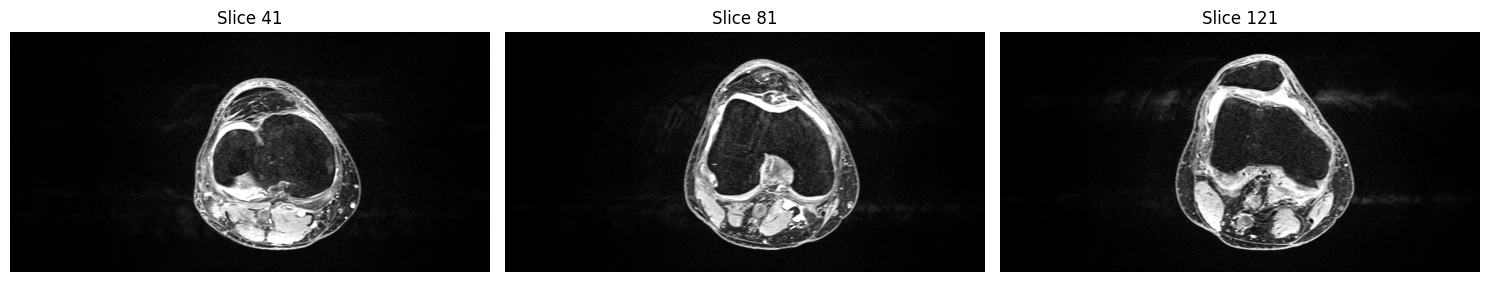

Rows × columns: 640 × 1280
Pixel spacing [row, column] (mm): [0.25, 0.25]
Missing or empty selected series: 0


In [16]:
axial_row = largest_series.loc[
    largest_series["plane"].eq("Axial")
].iloc[0]

folder = (
    ROOT / "train_series"
    / axial_row["StudyInstanceUID"]
    / axial_row["SeriesInstanceUID"]
)

headers = [
    (path, pydicom.dcmread(path, stop_before_pixels=True))
    for path in folder.glob("*.dcm")
]

orientation = np.asarray(
    headers[0][1].ImageOrientationPatient, dtype=float
)
normal = np.cross(orientation[:3], orientation[3:])
normal /= np.linalg.norm(normal)

headers.sort(
    key=lambda item: np.dot(
        np.asarray(item[1].ImagePositionPatient, dtype=float),
        normal,
    )
)

import matplotlib.pyplot as plt

indices = [len(headers) // 4, len(headers) // 2, 3 * len(headers) // 4]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, index in zip(axes, indices):
    ds = pydicom.dcmread(headers[index][0])
    image = ds.pixel_array.astype(np.float32)

    image = (
        image * float(getattr(ds, "RescaleSlope", 1))
        + float(getattr(ds, "RescaleIntercept", 0))
    )

    row_spacing, col_spacing = map(float, ds.PixelSpacing)
    low, high = np.percentile(image, [1, 99])

    ax.imshow(
        image,
        cmap="gray",
        vmin=low,
        vmax=high,
        aspect=row_spacing / col_spacing,
    )
    ax.set_title(f"Slice {index + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Rows × columns:", ds.Rows, "×", ds.Columns)
print("Pixel spacing [row, column] (mm):", ds.PixelSpacing)
print("Missing or empty selected series:", len(problems))

In [17]:
from tqdm.auto import tqdm

geometry_records = []

for _, row in tqdm(
    dataset_manifest.iterrows(),
    total=len(dataset_manifest),
    desc="Checking series geometry",
):
    record = {
        "StudyInstanceUID": row["StudyInstanceUID"],
        "SeriesInstanceUID": row["SeriesInstanceUID"],
        "plane": row["Anatomical_Plane"],
    }
    issues = []

    try:
        folder = ROOT / row["series_relative_path"]
        files = sorted(folder.glob("*.dcm"))

        if len(files) < 2:
            raise ValueError("Fewer than two DICOM files")

        headers = [
            pydicom.dcmread(path, stop_before_pixels=True)
            for path in files
        ]

        if any(int(getattr(ds, "NumberOfFrames", 1)) != 1
               for ds in headers):
            raise ValueError("Multi-frame DICOM requires separate handling")

        positions = np.asarray(
            [ds.ImagePositionPatient for ds in headers], dtype=float
        )
        orientations = np.asarray(
            [ds.ImageOrientationPatient for ds in headers], dtype=float
        )
        pixel_spacing = np.asarray(
            [ds.PixelSpacing for ds in headers], dtype=float
        )
        dimensions = {(int(ds.Rows), int(ds.Columns)) for ds in headers}

        if not all(np.isfinite(a).all() for a in
                   [positions, orientations, pixel_spacing]):
            raise ValueError("Non-finite geometry values")

        if (pixel_spacing <= 0).any():
            raise ValueError("Non-positive pixel spacing")

        if len(dimensions) != 1:
            issues.append("varying_dimensions")

        if not np.allclose(
            pixel_spacing, pixel_spacing[0], atol=1e-5, rtol=1e-4
        ):
            issues.append("varying_pixel_spacing")

        same_orientation = np.allclose(
            orientations, orientations[0], atol=1e-4, rtol=0
        )
        if not same_orientation:
            issues.append("varying_orientation")

        direction_a = orientations[0, :3]
        direction_b = orientations[0, 3:]

        if (
            not np.isclose(np.linalg.norm(direction_a), 1, atol=1e-3)
            or not np.isclose(np.linalg.norm(direction_b), 1, atol=1e-3)
            or abs(np.dot(direction_a, direction_b)) > 1e-3
        ):
            raise ValueError("Invalid orientation direction vectors")

        normal = np.cross(direction_a, direction_b)
        normal /= np.linalg.norm(normal)

        order = np.argsort(positions @ normal)
        steps = np.diff(positions[order], axis=0)
        spacing = steps @ normal
        median_spacing = float(np.median(spacing))

        if (spacing < 0.001).any():
            issues.append("near_duplicate_slice_positions")

        if not np.allclose(
            spacing, median_spacing, atol=0.01, rtol=0.01
        ):
            issues.append("irregular_slice_spacing")

        # Detect shifts within the image plane between slice origins.
        in_plane_steps = steps - spacing[:, None] * normal
        max_in_plane_shift = float(
            np.linalg.norm(in_plane_steps, axis=1).max()
        )

        if max_in_plane_shift > 0.1:
            issues.append("in_plane_origin_shift")

        record.update({
            "file_count": len(files),
            "min_spacing_mm": float(spacing.min()),
            "median_spacing_mm": median_spacing,
            "max_spacing_mm": float(spacing.max()),
            "max_in_plane_shift_mm": max_in_plane_shift,
        })

    except Exception as error:
        issues.append(f"read_or_geometry_error: {error}")

    record["issues"] = "; ".join(issues)
    record["needs_review"] = bool(issues)
    geometry_records.append(record)

geometry_checks = pd.DataFrame(geometry_records)

geometry_checks.to_csv(
    "/kaggle/working/series_geometry_checks.csv",
    index=False,
)

print("Series checked:", len(geometry_checks))
print("Series needing review:", geometry_checks["needs_review"].sum())

display(
    geometry_checks.loc[geometry_checks["needs_review"]]
)

Checking series geometry:   0%|          | 0/174 [00:00<?, ?it/s]

Series checked: 174
Series needing review: 0


,StudyInstanceUID,SeriesInstanceUID,plane,file_count,min_spacing_mm,median_spacing_mm,max_spacing_mm,max_in_plane_shift_mm,issues,needs_review


In [18]:
keys = ["StudyInstanceUID", "SeriesInstanceUID"]

dataset_manifest = dataset_manifest.merge(
    geometry_checks[
        keys + [
            "file_count",
            "median_spacing_mm",
            "needs_review",
        ]
    ],
    on=keys,
    how="left",
    validate="one_to_one",
)

assert dataset_manifest["needs_review"].notna().all()
assert not dataset_manifest["needs_review"].any()

dataset_manifest.to_csv(
    "/kaggle/working/dataset_manifest_seed42.csv",
    index=False,
)

print("Saved manifest with geometry checks:", len(dataset_manifest))

Saved manifest with geometry checks: 174
